# 03 · Label-quality audit (why accuracy plateaus near 94–95%)
Every baseline in notebook 02 lands at ~94%. Before building something heavier, check whether the
**labels** are the limit. This notebook uses *confident learning* (`cleanlab`) with out-of-fold predicted
probabilities (5-fold, **grouped by guest**) to find reviews whose given label contradicts their text/rating.

> **How to report this honestly.** Accuracy on a test set from which suspected-wrong rows were *removed by a similar
> model* is optimistic. Always show it next to the raw-label accuracy and have a human verify a sample of the flagged rows
> (`outputs/label_issues.csv`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import mlflow, numpy as np, pandas as pd, matplotlib.pyplot as plt
from cleanlab.filter import find_label_issues
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, OUT = ROOT / "data" / "processed", ROOT / "outputs"
SEED = 42
LABELS = ["negative", "neutral", "positive"]
MLFLOW_URI = f"sqlite:///{ROOT / 'mlflow.db'}"
pd.set_option("display.max_colwidth", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

full = pd.read_csv(PROC / "reviews_full.csv")
full["y"] = full.sentiment_label.map({l: i for i, l in enumerate(LABELS)})

def feats(fit_df, *dfs):
    v = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")
    o = OneHotEncoder(handle_unknown="ignore")
    f = lambda d, fit: hstack([(v.fit_transform if fit else v.transform)(d.review_text),
                               (o.fit_transform if fit else o.transform)(d[["rating_bin"]].astype(str))]).tocsr()
    return [f(fit_df, True)] + [f(d, False) for d in dfs]

## 1. Out-of-fold probabilities for every review

In [2]:
probs = np.zeros((len(full), 3))
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for a, b in cv.split(full, full.y, groups=full.guest_id):
    A, B = full.iloc[a], full.iloc[b]
    Xa, Xb = feats(A, B)
    probs[b] = LogisticRegression(C=1, max_iter=3000).fit(Xa, A.y).predict_proba(Xb)
print("out-of-fold accuracy vs given labels:", round((probs.argmax(1) == full.y).mean(), 4))

out-of-fold accuracy vs given labels: 0.9417


## 2. Which labels look wrong?

1,717 of 34,460 labels flagged (4.98%)


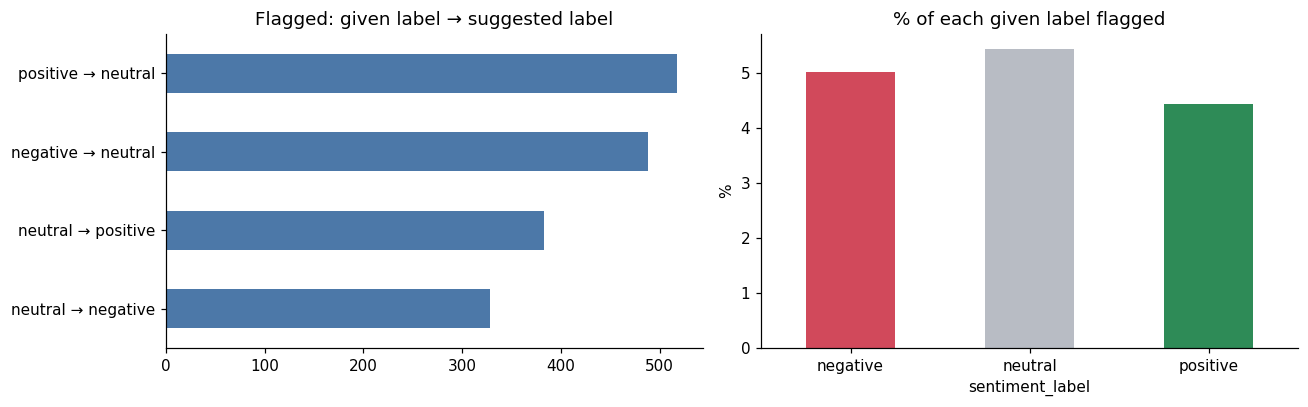

In [3]:
issues = find_label_issues(full.y.values, probs, filter_by="prune_by_noise_rate")
full["flagged"] = issues
full["suggested_label"] = np.array(LABELS)[probs.argmax(1)]
full["suggested_conf"] = probs.max(1)
flagged = full[full.flagged]
export = flagged[["review_id", "review_text", "rating_score", "sentiment_label", "suggested_label",
                  "suggested_conf", "split"]].sort_values("suggested_conf", ascending=False)
export.to_csv(OUT / "label_issues.csv", index=False)
print(f"{issues.sum():,} of {len(full):,} labels flagged ({100 * issues.mean():.2f}%)")

trans = (flagged.sentiment_label + " → " + flagged.suggested_label).value_counts()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
trans.sort_values().plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_title("Flagged: given label → suggested label")
flagged.groupby("sentiment_label").size().reindex(LABELS).div(full.groupby("sentiment_label").size().reindex(LABELS)).mul(100)\
       .plot.bar(ax=ax[1], color=[{"negative": "#D1495B", "neutral": "#B8BCC4", "positive": "#2E8B57"}[l] for l in LABELS], rot=0)
ax[1].set_title("% of each given label flagged"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

**Spot-check the most confident disagreements** (read them yourself — this is the evidence that matters):

In [4]:
export.head(8)[["review_text", "rating_score", "sentiment_label", "suggested_label", "suggested_conf"]].round(2)

,review_text,rating_score,sentiment_label,suggested_label,suggested_conf
3092,"Our time in Nottingham got off to a rocky start here. On the other hand, our arrival experience was delayed for no clear reason, which really affected our stay. Also, sadly, the housekeeping staff turned out to be un...",1.4,neutral,negative,1.0
24318,"We were disappointed that the location was disappointingly out of the way. On top of that, the rate we paid left a lot to be desired; we found better options nearby for less. Not sure we'd come back.",2.2,neutral,negative,1.0
11636,"Our time in Leicester got off to a rocky start here. On top of that, sadly, the breakfast turned out to be overpriced for the quality.",2.1,neutral,negative,1.0
16943,"This hotel made our time in London truly memorable. On the other hand, i was genuinely impressed that the pricing was excellent value. Plus, honestly, the fitness facilities was beautifully maintained. Would definite...",4.4,neutral,positive,1.0
14560,"This wasn't the experience we expected during our visit to Glasgow. On top of that, we were disappointed that the overall price was overpriced. Also, the check-in desk was frustrating, which really affected our stay.",2.2,neutral,negative,1.0
12275,"Sadly, the breakfast turned out to be underwhelming. The overall price was a poor deal, which really affected our stay. Meanwhile, unfortunately, the gym was outdated — it clearly needed some upkeep.",1.7,neutral,negative,1.0
25095,"The pricing left a lot to be desired; we found better options nearby for less. Also, the service team was dismissive, which really affected our stay. Left feeling pretty disappointed overall.",1.7,neutral,negative,1.0
16530,"The overall price was disappointing for the price, which really affected our stay. Sadly, the restaurant turned out to be overpriced for the quality. We'll be looking elsewhere next time.",1.8,neutral,negative,1.0


## 3. Accuracy: raw labels vs label-corrected
Four combinations (train on raw/clean × test on raw/clean-subset). **B** is the honest headline number.

In [5]:
tr, va, te = [full[full.split == s] for s in ("train", "val", "test")]
tr_clean = tr[~tr.flagged]
tr_clean.drop(columns=["y"]).to_csv(PROC / "train_clean.csv", index=False)     # used by notebook 04 (--clean-train)
keep = ~te.flagged.values
Xr, Xte = feats(tr, te); Xc, Xte_c = feats(tr_clean, te)
p_raw = LogisticRegression(C=1, max_iter=3000).fit(Xr, tr.y).predict(Xte)
p_cln = LogisticRegression(C=1, max_iter=3000).fit(Xc, tr_clean.y).predict(Xte_c)
acc = {"A_train_raw__test_raw": accuracy_score(te.y, p_raw),
       "B_train_clean__test_raw": accuracy_score(te.y, p_cln),
       "C_train_raw__test_clean_subset": accuracy_score(te.y[keep], p_raw[keep]),
       "D_train_clean__test_clean_subset": accuracy_score(te.y[keep], p_cln[keep])}
table = pd.DataFrame({"train labels": ["raw", "clean", "raw", "clean"], "test labels": ["raw", "raw", "clean subset", "clean subset"],
                      "accuracy %": [round(100 * v, 2) for v in acc.values()]}, index=list(acc))
print(f"test rows: {len(te):,}; flagged & removed from the clean subset: {(~keep).sum()}")
table

test rows: 4,923; flagged & removed from the clean subset: 231


,train labels,test labels,accuracy %
A_train_raw__test_raw,raw,raw,94.54
B_train_clean__test_raw,clean,raw,94.70
C_train_raw__test_clean_subset,raw,clean subset,99.17
D_train_clean__test_clean_subset,clean,clean subset,99.36


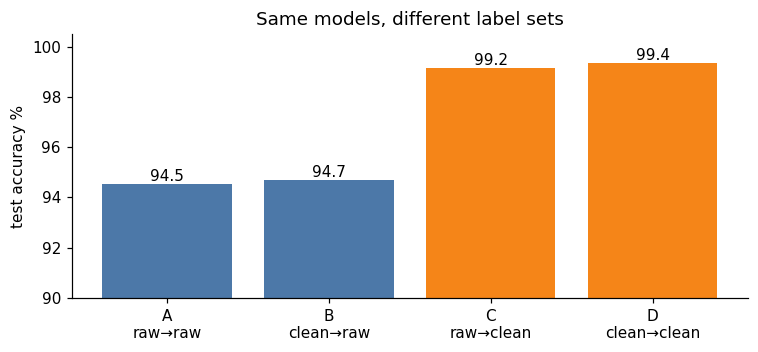

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.bar(["A\nraw→raw", "B\nclean→raw", "C\nraw→clean", "D\nclean→clean"], [100 * v for v in acc.values()],
       color=["#4C78A8", "#4C78A8", "#F58518", "#F58518"])
ax.set_ylim(90, 100.5)
for i, v in enumerate(acc.values()): ax.text(i, 100 * v + .1, f"{100 * v:.1f}", ha="center")
ax.set(title="Same models, different label sets", ylabel="test accuracy %")
plt.tight_layout(); plt.show()

In [7]:
summary = {"n_total": len(full), "n_flagged": int(issues.sum()), "pct_flagged": round(100 * issues.mean(), 2),
           "flagged_by_given_label": flagged.sentiment_label.value_counts().to_dict(),
           "flagged_given_to_suggested": trans.to_dict(),
           "accuracy": {**{k: round(v, 4) for k, v in acc.items()}, "test_rows_total": len(te), "test_rows_flagged": int((~keep).sum())}}
(OUT / "label_noise_summary.json").write_text(json.dumps(summary, indent=2))
mlflow.set_tracking_uri(MLFLOW_URI); mlflow.set_experiment("guest-sentiment-label-noise")
with mlflow.start_run(run_name="cleanlab_logreg"):
    mlflow.log_params({"detector": "cleanlab prune_by_noise_rate", "cv": "5-fold grouped by guest"})
    mlflow.log_metrics({"pct_flagged": summary["pct_flagged"], **acc})
print(json.dumps(summary["accuracy"], indent=2))

2026/10/10 20:31:02 INFO mlflow.tracking.fluent: Experiment with name 'guest-sentiment-label-noise' does not exist. Creating a new experiment.


{
  "A_train_raw__test_raw": 0.9454,
  "B_train_clean__test_raw": 0.947,
  "C_train_raw__test_clean_subset": 0.9917,
  "D_train_clean__test_clean_subset": 0.9936,
  "test_rows_total": 4923,
  "test_rows_flagged": 231
}


## Take-aways
* ~5% of labels contradict their own text; flagged rows explain the large majority of test errors (see notebook 05).
* **Defensible reporting:** quote **B** (≈94–95%) as the headline, mention **D** (≈99%) as *"accuracy on a test set with suspected
  mislabels removed"*, and verify a random sample of flagged vs unflagged rows by hand before claiming corrected labels.
* `train_clean.csv` is saved so BERT can be trained on cleaned labels (notebook 04).